In [1]:
import sys
import os
import math
from typing import NamedTuple

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), 'import'))

from utils import read_utils
from utils import plot_utils
from utils import train_utils
from utils import artificializer

from models import bom
from models import hgm

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/Workspaces/UNIVIE/JetBrains/DataSpell/MSc_Thesis/worm-2025-fieseler/import/models/hgm.py'>

# Functions

In [3]:
class Lambdas(NamedTuple):
	loss_lambdas: tuple[float, float]
	reg_lambdas: tuple[float, float]
	cca_lambdas: tuple[float, float]

class PrepData(NamedTuple):
	N_mean: tuple[float, ...]
	N_std: tuple[float, ...]
	B_hl_mean: tuple[float, ...] | None = None
	B_hl_std: tuple[float, ...] | None = None

In [4]:
def train_model(model, splits, N, B_ll, B_hl, hyperparameters=None):
	#region hyperparamters ===============================================================
	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1), jax.random.PRNGKey(2), jax.random.PRNGKey(3)

	if hyperparameters is None:
		hyperparameters = {
			'max_epochs': 2000,
			'max_patience': 2000 / 4,
			'learning_rate': 1E-2,
			'w1_reg_lambda': 0.0,
			'w2_reg_lambda': 0.0,
			'ccadiag_lambda': 0.6,
			'ccaunit_lambda': 1 - 0.6,
			'loss1_lambda': 0.5,
			'loss2_lambda': 1. - 0.5,
			'dimensions': 2
		}

	max_epochs = hyperparameters['max_epochs']
	max_patience = hyperparameters['max_patience']

	learning_rate = hyperparameters['learning_rate']

	n_dimensions = hyperparameters['dimensions']

	lambdas = Lambdas(
		loss_lambdas=(hyperparameters['loss1_lambda'], hyperparameters['loss2_lambda']),
		reg_lambdas=(hyperparameters['w1_reg_lambda'], hyperparameters['w2_reg_lambda']),
		cca_lambdas=(hyperparameters['ccadiag_lambda'], hyperparameters['ccaunit_lambda'])
	)
	#endregion ===========================================================================

	n_neurons = N.shape[1]
	n_behaviors_hl = B_hl.shape[1]
	n_behaviors_ll = B_ll.shape[1]

	# training loop =============================
	params_per_split = list()
	neuron_scores_per_split = list()
	losses_per_split = list()
	losses_tr_per_split = list()
	mpe_losses_per_split = list()
	mpe_losses_tr_per_split = list()
	for s_id, (train, eval) in enumerate(splits):
		#region splitting and initializing (this also moves the data to the GPU) ==========================
		N_train, N_eval = jnp.array(N[train]), jnp.array(N[eval])
		B_hl_train, B_hl_eval = jnp.array(B_hl[train]), jnp.array(B_hl[eval])
		B_ll_train, B_ll_eval = jnp.array(B_ll[train]), jnp.array(B_ll[eval])

		prep_data_train = PrepData(
			N_mean=tuple((map(float, N_train.mean(axis=0)))),
			N_std=tuple((map(float, jnp.where((N_std := jnp.std(N_train, axis=0)) == 0.0, 1.0, N_std)))),
			B_hl_mean=tuple((map(float, B_hl_train.mean(axis=0)))),
			B_hl_std=tuple((map(float, jnp.where((B_hl_std := jnp.std(B_hl_train, axis=0)) == 0.0, 1.0, B_hl_std))))
		)
		prep_data_eval = PrepData(
			N_mean=tuple((map(float, N_eval.mean(axis=0)))),
			N_std=tuple((map(float, jnp.where((N_std := jnp.std(N_eval, axis=0)) == 0.0, 1.0, N_std)))),
			B_hl_mean=tuple((map(float, B_hl_eval.mean(axis=0)))),
			B_hl_std=tuple((map(float, jnp.where((B_hl_std := jnp.std(B_hl_eval, axis=0)) == 0.0, 1.0, B_hl_std))))
		)

		params = model.init_params(seeds,
								   (n_neurons, n_dimensions),
								   (n_behaviors_hl, n_dimensions),
								   (n_behaviors_ll, n_neurons),
								   * ((n_dimensions, n_neurons),) if model.get_type() else ())

		# optimizer = optax.adam(learning_rate=optax.cosine_decay_schedule(
		# 	init_value=learning_rate,
		# 	decay_steps=max_epochs,
		# 	alpha=1E-2
		# ))
		optimizer = optax.adam(learning_rate)
		opt_state = optimizer.init(params)
		#endregion ========================================================================================

		losses = [model.loss_fn(params, N_eval, B_ll_eval, B_hl_eval, lambdas, prep_data_eval).item()]
		losses_tr = [model.loss_fn(params, N_train, B_ll_train, B_hl_train, lambdas, prep_data_train).item()]
		mpe_losses = [model.mpe_loss_fn(params, N_eval, B_ll_eval, prep_data_eval).item()]
		mpe_losses_tr = [model.mpe_loss_fn(params, N_train, B_ll_train, prep_data_train).item()]

		best_params = params
		best_loss = sys.float_info.max
		best_loss_tr = sys.float_info.max
		best_mpe_loss = sys.float_info.max
		best_mpe_loss_tr = sys.float_info.max

		# lr_step = 0
		patience = 0
		for epoch in range(max_epochs):
			params, opt_state = model.update(optimizer.update, opt_state, params, N_train, B_ll_train, B_hl_train, lambdas, prep_data_train)

			loss = model.loss_fn(params, N_eval, B_ll_eval, B_hl_eval, lambdas, prep_data_eval).item()
			loss_tr = model.loss_fn(params, N_train, B_ll_train, B_hl_train, lambdas, prep_data_train).item()
			mpe_loss = model.mpe_loss_fn(params, N_eval, B_ll_eval, prep_data_eval).item()
			mpe_loss_tr = model.mpe_loss_fn(params, N_train, B_ll_train, prep_data_train).item()

			#region early stopping ===========================================================================
			if epoch >= max_patience:  # give it an initial time
				if loss < best_loss:
					patience = 0

					best_params = params
					best_loss = loss
					best_loss_tr = loss_tr
					best_mpe_loss = mpe_loss
					best_mpe_loss_tr = mpe_loss_tr
				else:
					patience += 1
					if patience > max_patience:
						params = best_params
						losses = losses + [best_loss for _ in range(max_epochs - epoch)]
						losses_tr = losses_tr + [best_loss_tr for _ in range(max_epochs - epoch)]
						mpe_losses = mpe_losses + [best_mpe_loss for _ in range(max_epochs - epoch)]
						mpe_losses_tr = mpe_losses_tr + [best_mpe_loss_tr for _ in range(max_epochs - epoch)]

						print(f'Stopped after {epoch} epochs: ', end='')
						break

						# lr_step += 1
						# optimizer = optax.adam(learning_rate / (10 ** lr_step))
						# patience = 0
						# print(f'\nReduced learning rate from {learning_rate / (10 ** (lr_step - 1))} to {learning_rate / (10 ** lr_step)} after epoch {epoch} in split {s_id}', end='')
			#endregion =======================================================================================

			losses.append(loss)
			losses_tr.append(loss_tr)
			mpe_losses.append(mpe_loss)
			mpe_losses_tr.append(mpe_loss_tr)

		params_per_split.append(params)
		losses_per_split.append(losses)
		losses_tr_per_split.append(losses_tr)
		mpe_losses_per_split.append(mpe_losses)
		mpe_losses_tr_per_split.append(mpe_losses_tr)

		print(f'Split {s_id} completed. ', end='')

		# predicting and scoring ========================================================================
		score_per_neuron = model.score_fn(params, N_eval, B_ll_eval, prep_data_eval)
		neuron_scores_per_split.append(score_per_neuron)
		# ===============================================================================================

	# ===========================================

	return params_per_split, np.array(neuron_scores_per_split), np.array(losses_per_split), np.array(losses_tr_per_split), np.array(mpe_losses_per_split), np.array(mpe_losses_tr_per_split)

In [5]:
def train_models(model, filenames, discrete_states, eigenworms, traces):
	models_params = list()
	models_scores = list()
	models_losses = list()
	models_losses_tr = list()
	models_mpe_losses = list()
	models_mpe_losses_tr = list()

	for i in range(len(filenames)):
		print(f'\n{i+1}/{len(filenames)}: {filenames[i]} ', end='')

		splits = list(StratifiedKFold(n_splits=5).split(np.zeros(traces[i].shape[0]), discrete_states[i]['REV'].values))

		(params_per_split,
		 neuron_scores_per_split,
		 losses_per_split, losses_tr_per_split,
		 mpe_losses_per_split, mpe_losses_tr_per_split) = train_model(
			model, splits,
			jnp.array(traces[i].values),
			jnp.array(eigenworms[i].values),
			jnp.array(discrete_states[i].values))

		models_params.append(params_per_split)
		models_scores.append(neuron_scores_per_split)
		models_losses.append(losses_per_split)
		models_losses_tr.append(losses_tr_per_split)
		models_mpe_losses.append(mpe_losses_per_split)
		models_mpe_losses_tr.append(mpe_losses_tr_per_split)

	return models_params, models_scores, models_losses, models_losses_tr, models_mpe_losses, models_mpe_losses_tr

In [6]:
def assemble(filenames, traces, bom_models_scores, hgm_models_scores):
	neurons_labels = [traces[i].columns for i in range(len(filenames))]

	neuron_scores = dict()
	bom_models_avg_scores = [np.mean(scores, axis=0) for scores in bom_models_scores]
	hgm_models_avg_scores = [np.mean(scores, axis=0) for scores in hgm_models_scores]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, bom_models_avg_scores, hgm_models_avg_scores):
		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [7]:
def predict_wrapper(model, N, B_ll, params, neurons_labels):
	N_res_pred, N_res, N_rec = model.obtain(params,
											N, B_ll,
											PrepData(
												N_mean=tuple((map(float, N.mean(axis=0)))),
												N_std=tuple((map(float, jnp.where((N_std := jnp.std(N, axis=0)) == 0.0, 1.0, N_std)))),
											))
	return tuple(pd.DataFrame(data=traces, columns=neurons_labels) for traces in (N_res_pred, N_res, N_rec))

In [49]:
read_ids = [0, 4, 5, 6, 27, 30, 31, 32, 33]
# read_ids = [4]
plot_id = 4

dims = 2  # just for the comparison cca
dims_generation = 2
weights = (0.5, 2.)

# selection_n = ['DB01', 'VB02', 'RMDDR', 'RMDDL', 'SMDDR', 'SMDVR']  # high c portion for worm 33
# selection_n = ['VB02', 'SMDDR', 'SMDDL', 'RMDDR', 'RMDDL', 'SMDVR']  # high c portion for worm 24
# selection_n = ['DD01', 'VB02', 'SMDDR', 'DB01', 'RMDDR', 'AVAR', 'AVAL']
selection_n = ['VB02', 'RMDDR', 'AVAR', 'AVAL']
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']


artificial = False
gfp = False

# read & preprocess (GCamp & GFP)

In [9]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
file_ids_gcamp, filenames_gcamp, continuous_behaviors_gcamp, discrete_states_gcamp, eigenworms_gcamp, kymographs_gcamp, traces_gcamp = read_utils.get_data(path, read_ids)

for i in range(len(filenames_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	traces_gcamp[i] = traces_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]


if gfp:
	path_gfp = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gfp')
	file_ids_gfp, filenames_gfp, continuous_behaviors_gfp, discrete_states_gfp, eigenworms_gfp, kymographs_gfp, traces_gfp = read_utils.get_data(path_gfp)

	for i in range(len(filenames_gfp)):
		mask = eigenworms_gfp[i].notna().all(axis=1)
		#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
		discrete_states_gfp[i] = discrete_states_gfp[i][mask]
		eigenworms_gfp[i] = eigenworms_gfp[i][mask]
		traces_gfp[i] = traces_gfp[i][mask]

		#kymographs_gfp[i] = kymographs_gfp[i][mask]
		#filenames_gfp[i] = filenames_gfp[i][mask]

	discrete_states_gfp = [ds[selection_bhl] for ds in discrete_states_gfp]

# ARTIFICIAL DATA

In [10]:
if artificial:
	filenames_art = list()
	discrete_states_art = discrete_states_gcamp.copy()
	eigenworms_art = eigenworms_gcamp.copy()
	neural_modes_art = list()
	traces_reconstructed_art = list()
	traces_residual_art = list()
	traces_art = list()
	for i in range(len(filenames_gcamp)):
		(filename_art,
		 neural_modes_art_,
		 traces_reconstructed_art_,
		 traces_residual_art_,
		 traces_art_,
		 params_art_,
		 params_cca_art_) = artificializer.artificialize(weights, hgm,
														 filenames_gcamp[i],
														 traces_gcamp[i].columns,
														 eigenworms_art[i],
														 discrete_states_art[i],
														 n_dimensions=dims_generation)
		filenames_art.append(filename_art)
		neural_modes_art.append(neural_modes_art_)
		traces_reconstructed_art.append(traces_reconstructed_art_)
		traces_residual_art.append(traces_residual_art_)
		traces_art.append(traces_art_)

In [11]:
if artificial:
	plot_utils.plot_traces(f'[{filenames_art[plot_id]}] traces residuals artificial',
						   discrete_states_art[plot_id]['REV'],
						   traces_residual_art[plot_id][selection_n],
						   n_plots=len(selection_n), plots_per_row=2, ylimits=None)

In [12]:
if artificial:
	# train bom art

	(bom_models_params_art,
	 bom_models_scores_art,
	 bom_models_losses_art, bom_models_losses_tr_art,
	 bom_models_mpe_losses_art, bom_models_mpe_losses_tr_art) = train_models(
		bom,
		filenames_art,
		discrete_states_art,
		eigenworms_art,
		traces_art)

In [13]:
if artificial:
	# train hgm art

	(hgm_models_params_art,
	 hgm_models_scores_art,
	 hgm_models_losses_art, hgm_models_losses_tr_art,
	 hgm_models_mpe_losses_art, hgm_models_mpe_losses_tr_art) = train_models(
		hgm,
		filenames_art,
		discrete_states_art,
		eigenworms_art,
		traces_art)

In [14]:
if artificial:
	plot_utils.plot_losses_splits('artificial hgm vs bom: mpe train',
								  filenames_art,
								  hgm_models_mpe_losses_tr_art, bom_models_mpe_losses_tr_art,
								  plots_per_row=4, ylimits=None)

In [15]:
if artificial:
	plot_utils.plot_losses_splits('artificial hgm vs bom: mpe test',
								  filenames_art,
								  hgm_models_mpe_losses_art, bom_models_mpe_losses_art,
								  plots_per_row=4, ylimits=None)

### performance

In [16]:
if artificial:
	# assemble_art

	neuron_scores_art = assemble(filenames_art, traces_art, bom_models_scores_art, hgm_models_scores_art)

In [17]:
if artificial:
	plot_utils.plot_performance_plot(neuron_scores_art, None,
									 limits=None, content_size=20)

In [18]:
if artificial:
	plot_utils.plot_improvement_plot(neuron_scores_art, None,
									 limits=None, content_size=20)

### traces check

In [19]:
if artificial:
	bom_pres_res_rec_art = [[
		predict_wrapper(bom, jnp.array(traces_art[i]), jnp.array(eigenworms_art[i]), params, traces_art[i].columns) for params in bom_models_params_art[i]
	] for i in range(len(traces_art))]

	hgm_pres_res_rec_art = [[
		predict_wrapper(hgm, jnp.array(traces_art[i]), jnp.array(eigenworms_art[i]), params, traces_art[i].columns) for params in hgm_models_params_art[i]
	] for i in range(len(traces_art))]

In [20]:
# if artificial:
# 	# best improvements
# 	neuron_diffs = {key: np.mean(neuron_scores_art[key][1] - neuron_scores_art[key][0]) for key in neuron_scores_art.keys()}
# 	selection_n = [label for label in list(reversed(list(np.array(list(neuron_diffs.keys()))[np.argsort(np.array(list(neuron_diffs.values())))]))) if label in traces_art[plot_id].columns][:4]
#
# 	# best hgm scores
# 	neuron_hgmss = {key: np.mean(neuron_scores_art[key][1]) for key in neuron_scores_art.keys()}
# 	selection_n = [label for label in list(reversed(list(np.array(list(neuron_hgmss.keys()))[np.argsort(np.array(list(neuron_hgmss.values())))]))) if label in traces_art[plot_id].columns][:4]

In [21]:
if artificial:
	plot_utils.plot_traces_x_splits(
		f'{filenames_art[plot_id]} art hgm & bom definitions manifold',
		discrete_states_art[plot_id]['REV'],
		traces_art[plot_id][selection_n],
		[hgm_pres_res_rec_art[plot_id][i][2][selection_n] for i in range(5)],
		[bom_pres_res_rec_art[plot_id][i][2][selection_n] for i in range(5)],
		plots_per_row=2, ylimits=None)

	plot_utils.plot_traces_x_splits(
		f'{filenames_art[plot_id]} art hgm & bom definitions residuals',
		discrete_states_art[plot_id]['REV'],
		traces_art[plot_id][selection_n],
		[hgm_pres_res_rec_art[plot_id][i][1][selection_n] for i in range(5)],
		[bom_pres_res_rec_art[plot_id][i][1][selection_n] for i in range(5)],
		plots_per_row=2, ylimits=None)

In [22]:
if artificial:
	for i in range(5):
		plot_utils.plot_traces_comparisons(
			f'{filenames_art[plot_id]} split {i} art hgm & bom predictions residuals',
			discrete_states_art[plot_id]['REV'],
			[hgm_pres_res_rec_art[plot_id][i][1][selection_n], hgm_pres_res_rec_art[plot_id][i][0][selection_n]],
			[bom_pres_res_rec_art[plot_id][i][1][selection_n], bom_pres_res_rec_art[plot_id][i][0][selection_n]],
			plots_per_row=1, ylimits=None)

# GCAMP

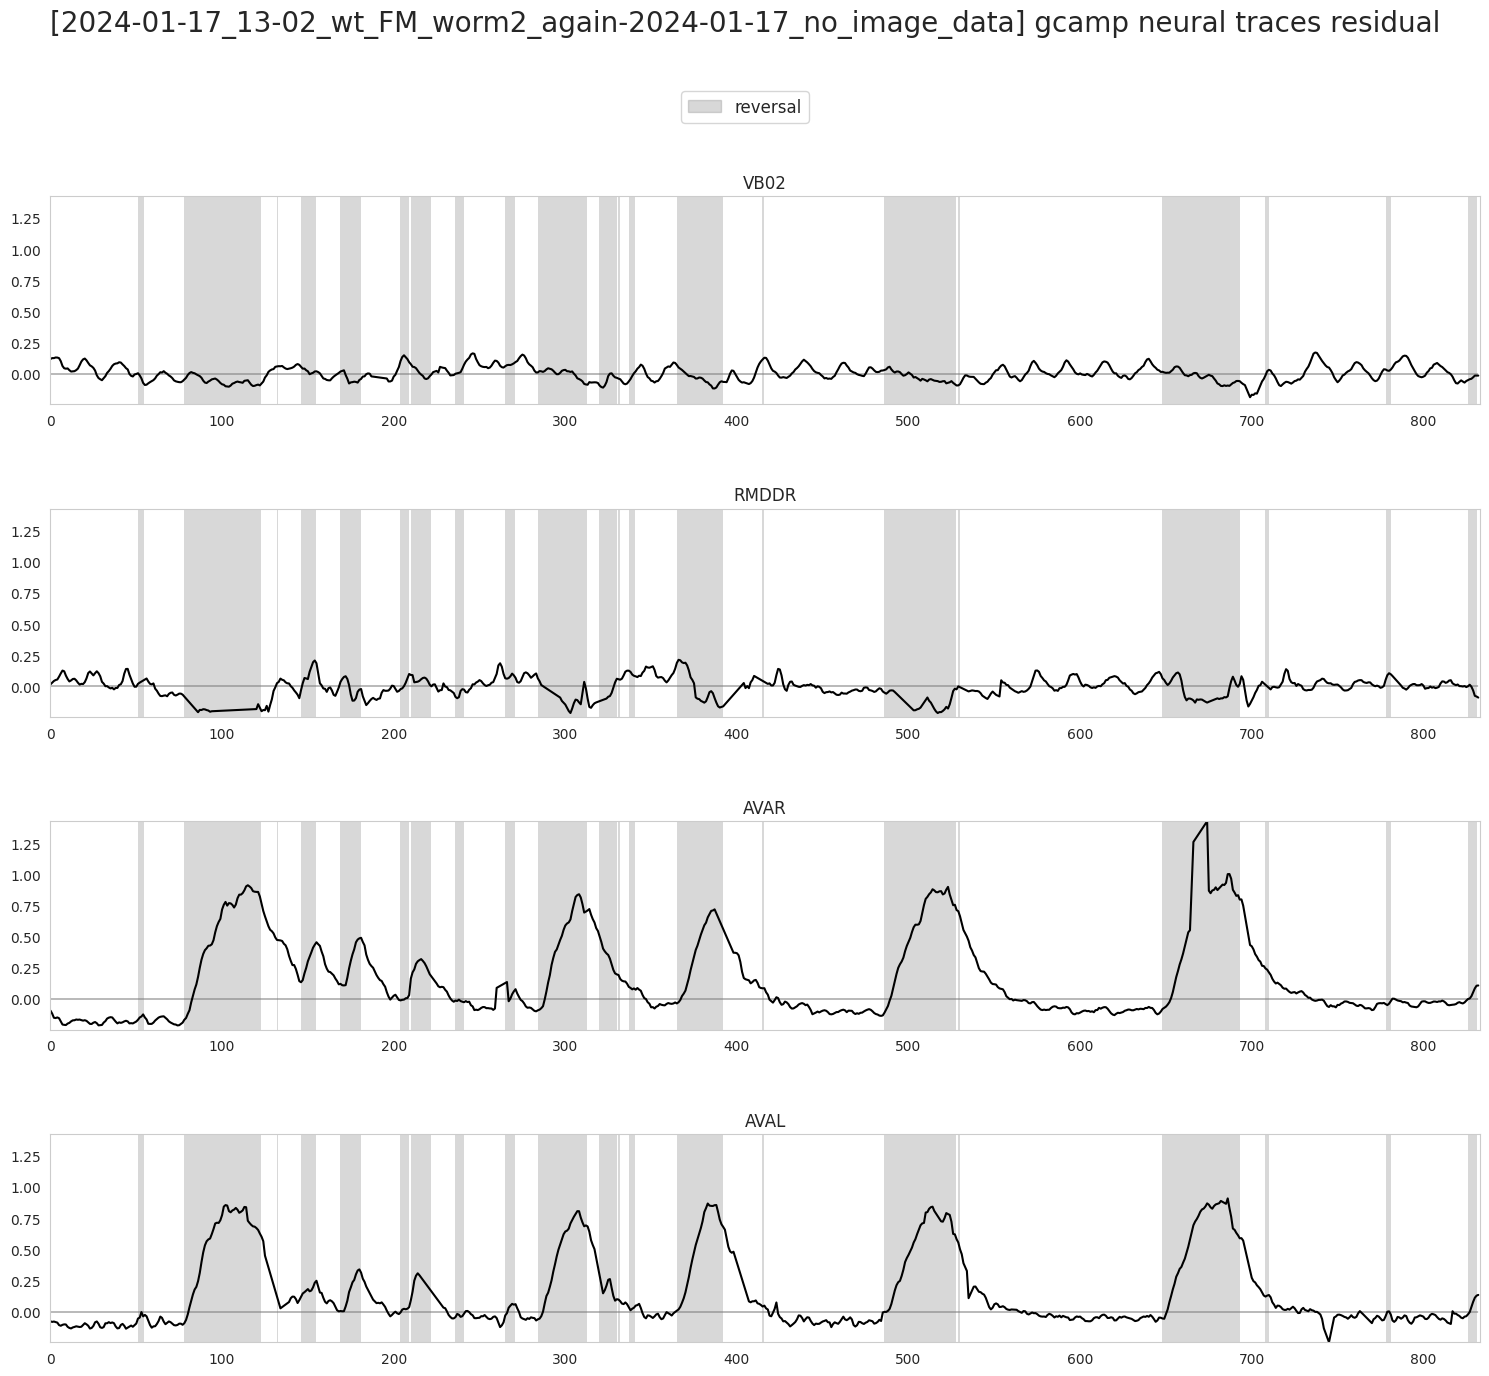

In [23]:
plot_utils.plot_traces(f'[{filenames_gcamp[file_ids_gcamp.index(plot_id)]}] gcamp neural traces',
					   discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
					   traces_gcamp[file_ids_gcamp.index(plot_id)][selection_n],
					   plots_per_row=1, ylimits=None)

### BOM

In [24]:
(bom_models_params_gcamp,
 bom_models_scores_gcamp,
 bom_models_losses_gcamp, bom_models_losses_tr_gcamp,
 bom_models_mpe_losses_gcamp, bom_models_mpe_losses_tr_gcamp) = train_models(
	bom,
	filenames_gcamp,
	discrete_states_gcamp,
	eigenworms_gcamp,
	traces_gcamp)


1/9: ZIM2165_Gcamp7b_worm3-2022_11_28_no_image_data Stopped after 1027 epochs: Split 0 completed. Stopped after 1107 epochs: Split 1 completed. Stopped after 1102 epochs: Split 2 completed. Stopped after 1002 epochs: Split 3 completed. Stopped after 1036 epochs: Split 4 completed. 
2/9: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data Stopped after 1001 epochs: Split 0 completed. Stopped after 1013 epochs: Split 1 completed. Stopped after 1081 epochs: Split 2 completed. Stopped after 1534 epochs: Split 3 completed. Stopped after 1002 epochs: Split 4 completed. 
3/9: ZIM2165_Gcamp7b_worm9-2022-12-05_no_image_data Stopped after 1006 epochs: Split 0 completed. Stopped after 1456 epochs: Split 1 completed. Split 2 completed. Split 3 completed. Stopped after 1149 epochs: Split 4 completed. 
4/9: 2024-01-30_16-32_wt_worm1-2024-01-30_no_image_data Stopped after 1102 epochs: Split 0 completed. Split 1 completed. Stopped after 1004 epochs: Split 2 completed. Stopped after 1099 epoch

### HGM

In [25]:
(hgm_models_params_gcamp,
 hgm_models_scores_gcamp,
 hgm_models_losses_gcamp, hgm_models_losses_tr_gcamp,
 hgm_models_mpe_losses_gcamp, hgm_models_mpe_losses_tr_gcamp) = train_models(
	hgm,
	filenames_gcamp,
	discrete_states_gcamp,
	eigenworms_gcamp,
	traces_gcamp)


1/9: ZIM2165_Gcamp7b_worm3-2022_11_28_no_image_data Stopped after 1496 epochs: Split 0 completed. Stopped after 1068 epochs: Split 1 completed. Stopped after 1029 epochs: Split 2 completed. Stopped after 1348 epochs: Split 3 completed. Stopped after 1056 epochs: Split 4 completed. 
2/9: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data Stopped after 1054 epochs: Split 0 completed. Stopped after 1081 epochs: Split 1 completed. Stopped after 1056 epochs: Split 2 completed. Stopped after 1679 epochs: Split 3 completed. Stopped after 1287 epochs: Split 4 completed. 
3/9: ZIM2165_Gcamp7b_worm9-2022-12-05_no_image_data Stopped after 1040 epochs: Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Stopped after 1086 epochs: Split 4 completed. 
4/9: 2024-01-30_16-32_wt_worm1-2024-01-30_no_image_data Stopped after 1164 epochs: Split 0 completed. Split 1 completed. Stopped after 1107 epochs: Split 2 completed. Stopped after 1003 epochs: Split 3 completed. Stopp

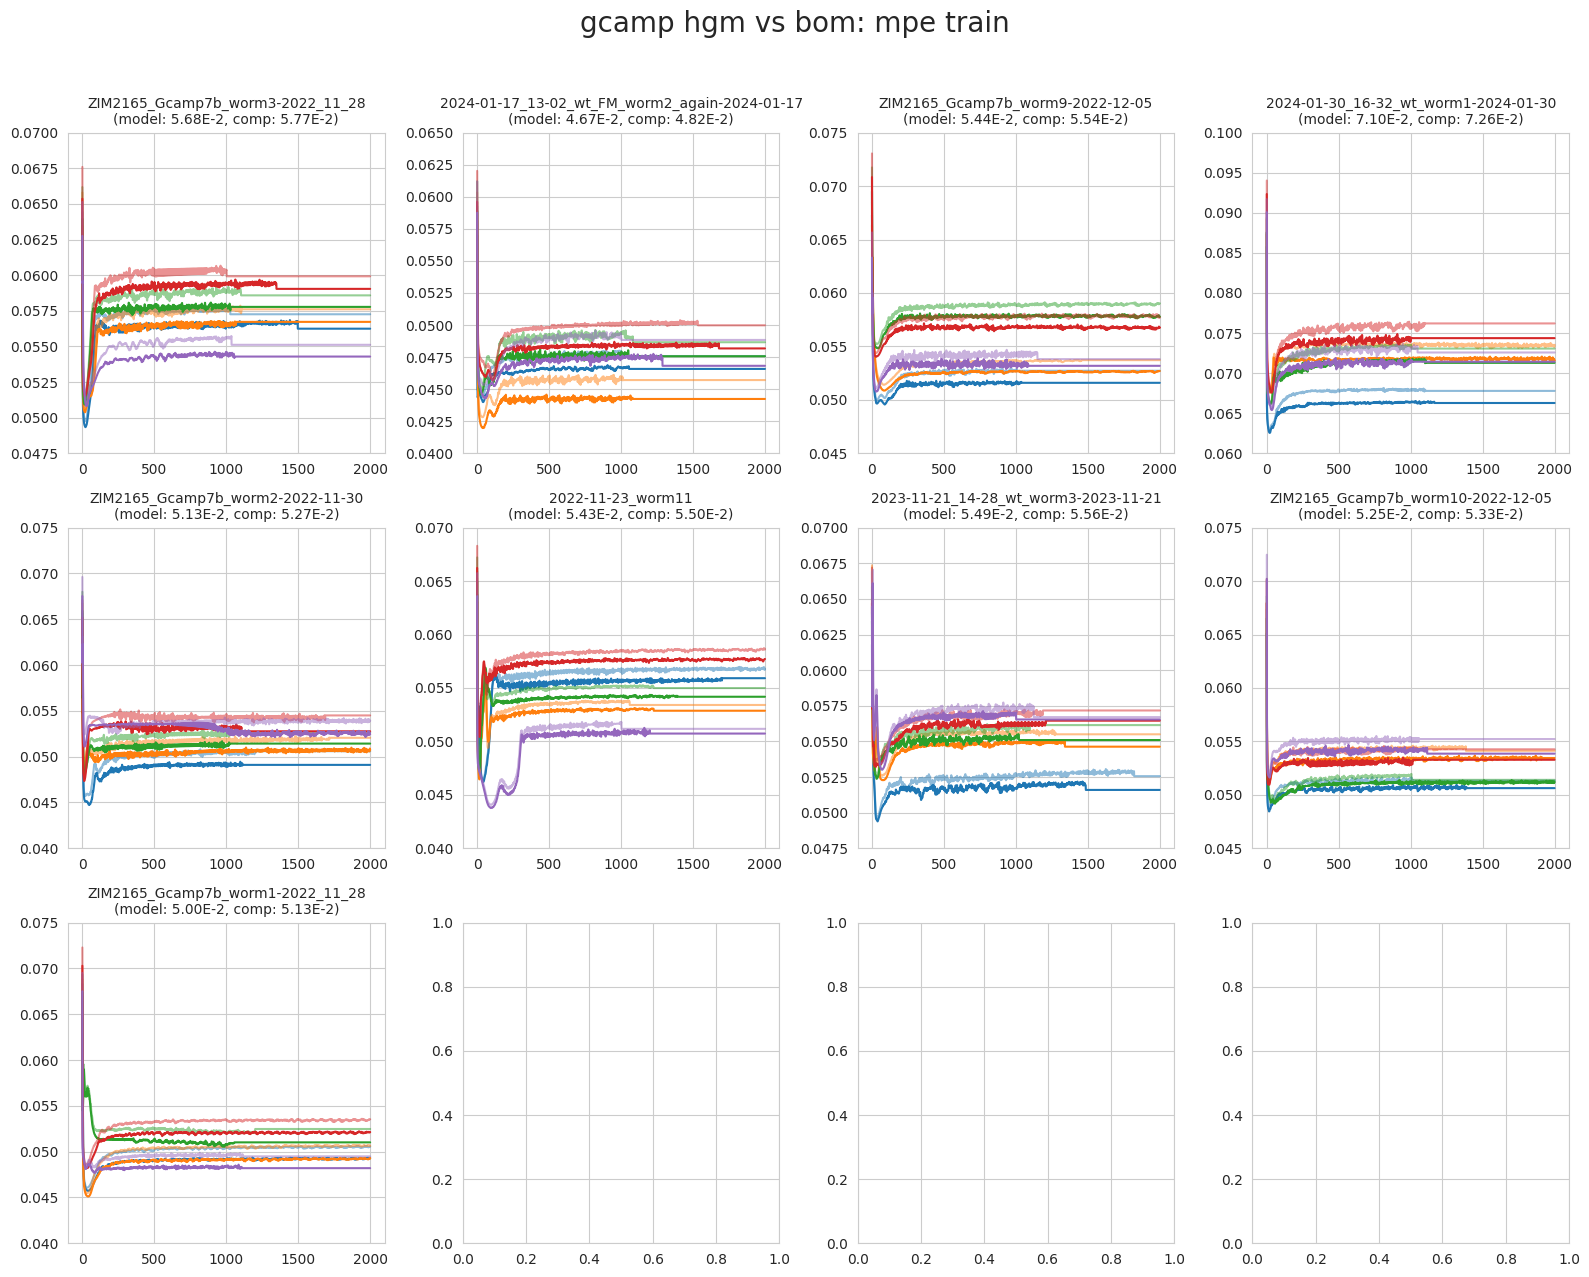

In [32]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: mpe train',
							  filenames_gcamp,
							  hgm_models_mpe_losses_tr_gcamp, bom_models_mpe_losses_tr_gcamp,
							  plots_per_row=4, ylimits=None)

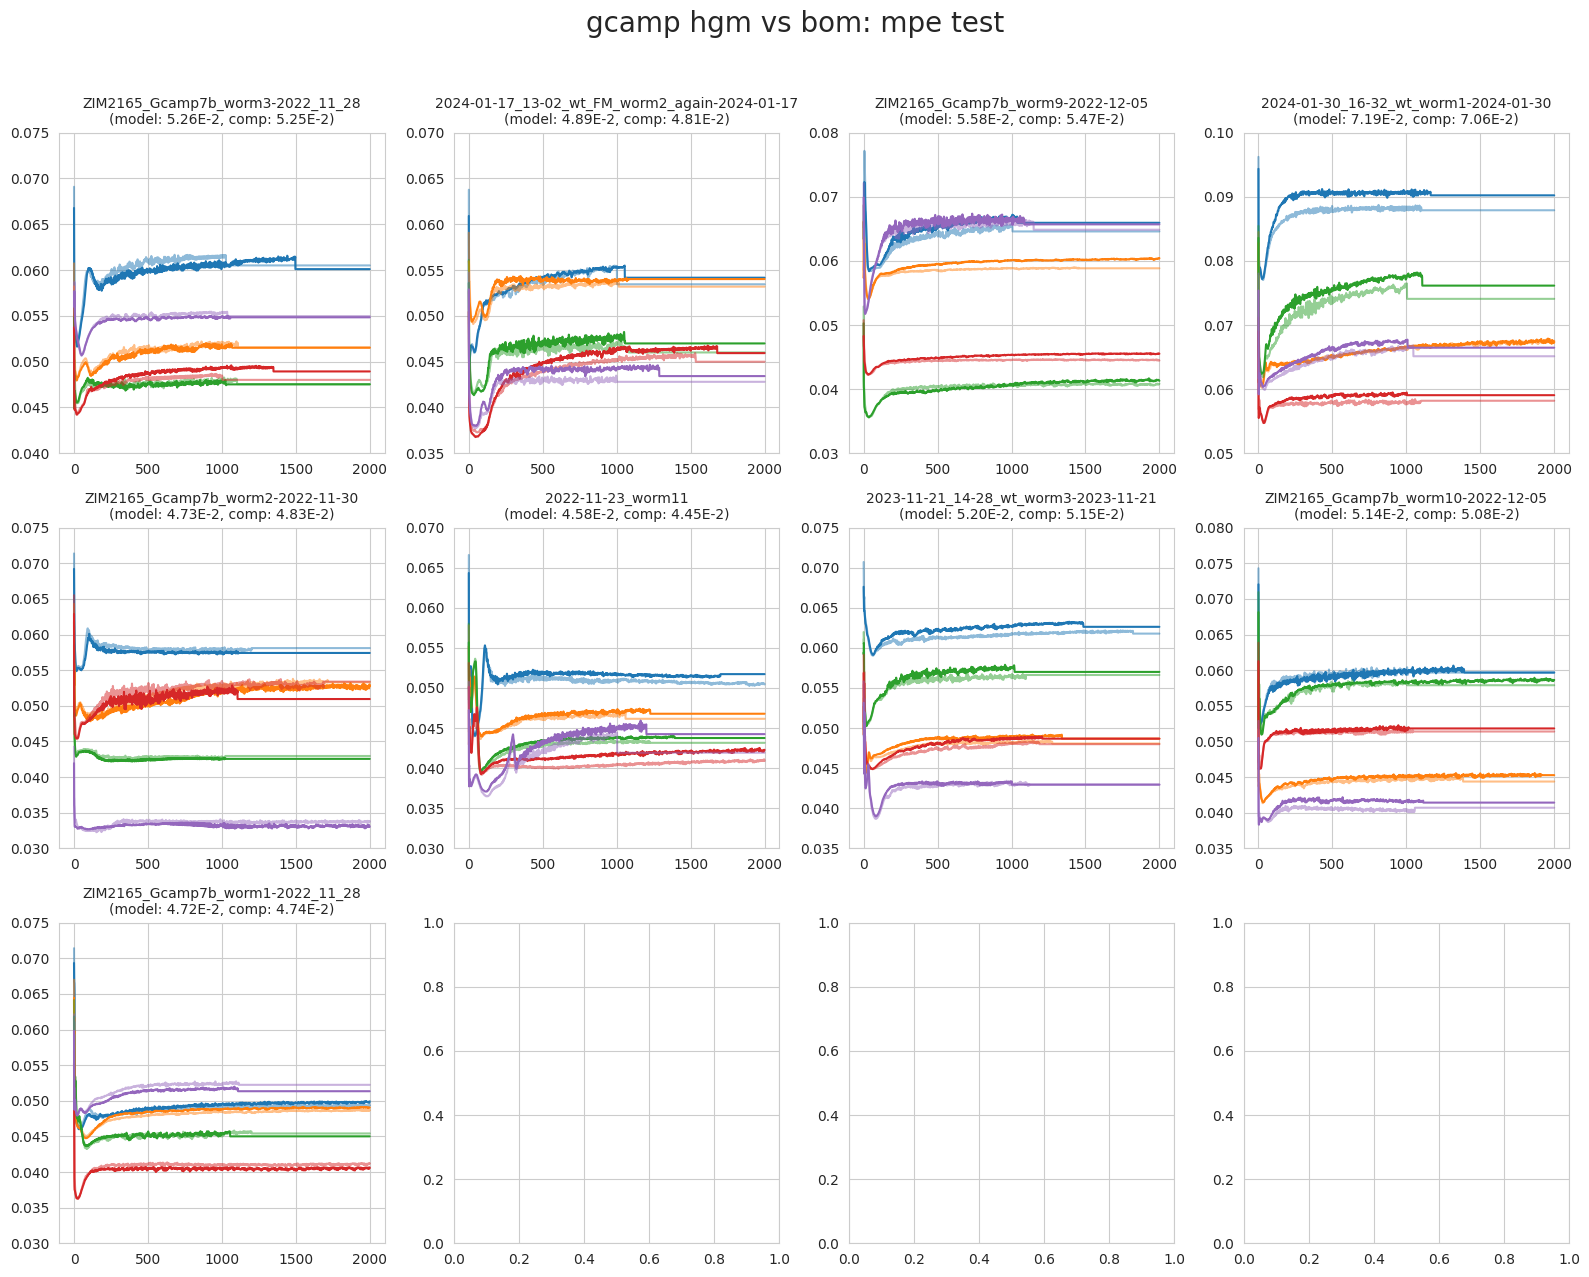

In [33]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: mpe test',
							  filenames_gcamp,
							  hgm_models_mpe_losses_gcamp, bom_models_mpe_losses_gcamp,
							  plots_per_row=4, ylimits=None)

### performance

In [28]:
neuron_scores_gcamp = assemble(filenames_gcamp, traces_gcamp, bom_models_scores_gcamp, hgm_models_scores_gcamp)

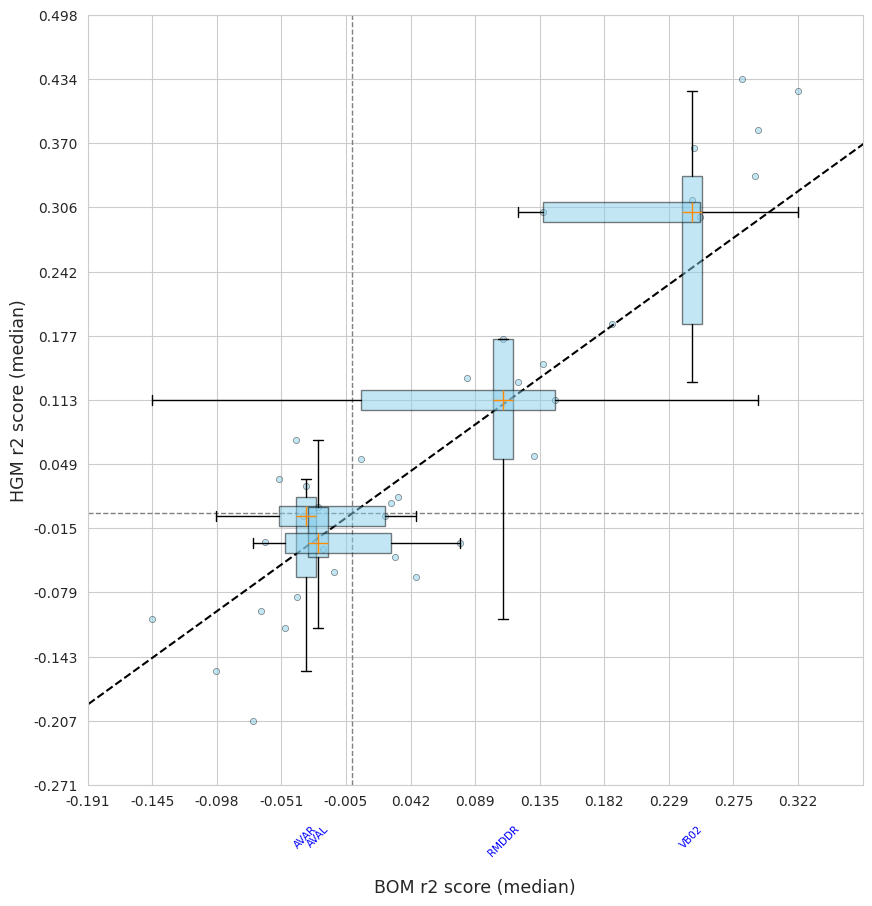

In [43]:
plot_utils.plot_performance_plot({key: neuron_scores_gcamp[key] for key in selection_n}, None,
								 limits=None, content_size=20)

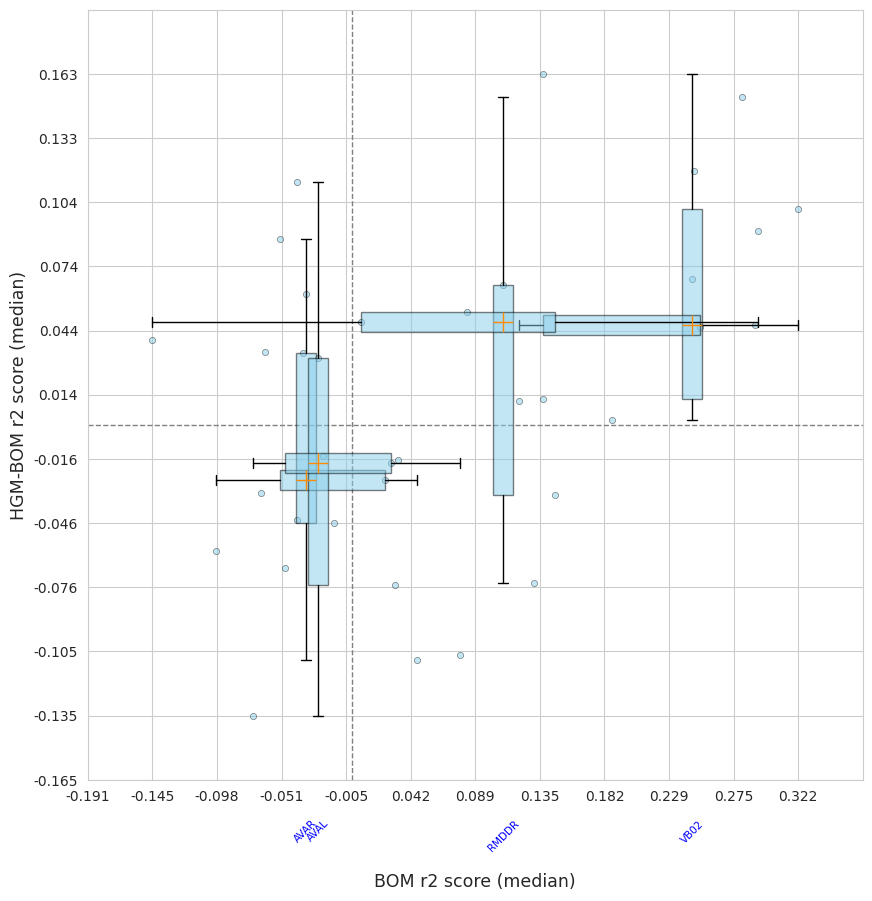

In [42]:
plot_utils.plot_improvement_plot({key: neuron_scores_gcamp[key] for key in selection_n}, None,
								 limits=None, content_size=20)

### traces check

In [44]:
bom_pres_res_rec_gcamp = [[
	predict_wrapper(bom, jnp.array(traces_gcamp[i]), jnp.array(eigenworms_gcamp[i]), params, traces_gcamp[i].columns) for params in bom_models_params_gcamp[i]
] for i in range(len(traces_gcamp))]

hgm_pres_res_rec_gcamp = [[
	predict_wrapper(hgm, jnp.array(traces_gcamp[i]), jnp.array(eigenworms_gcamp[i]), params, traces_gcamp[i].columns) for params in hgm_models_params_gcamp[i]
] for i in range(len(traces_gcamp))]

In [50]:
_, _, cca_rec_gcamp, _, _, _, _, _ = train_utils.get_manifolds(traces_gcamp, discrete_states_gcamp, n_cc=dims, n_pc=0)
cca_res_gcamp = [pd.DataFrame(data=trace_gcamp.values - cca_rec_gcamp_.values, columns=trace_gcamp.columns) for trace_gcamp, cca_rec_gcamp_ in zip(traces_gcamp, cca_rec_gcamp)]

In [45]:
# # best improvements
# neuron_diffs = {key: np.mean(neuron_scores_gcamp[key][1] - neuron_scores_gcamp[key][0]) for key in neuron_scores_gcamp.keys()}
# selection_n = [label for label in list(reversed(list(np.array(list(neuron_diffs.keys()))[np.argsort(np.array(list(neuron_diffs.values())))]))) if label in traces_gcamp[plot_id].columns][:10]
#
# # best hgm scores
# neuron_hgmss = {key: np.mean(neuron_scores_gcamp[key][1]) for key in neuron_scores_gcamp.keys()}
# selection_n = [label for label in list(reversed(list(np.array(list(neuron_hgmss.keys()))[np.argsort(np.array(list(neuron_hgmss.values())))]))) if label in traces_gcamp[plot_id].columns][:10]

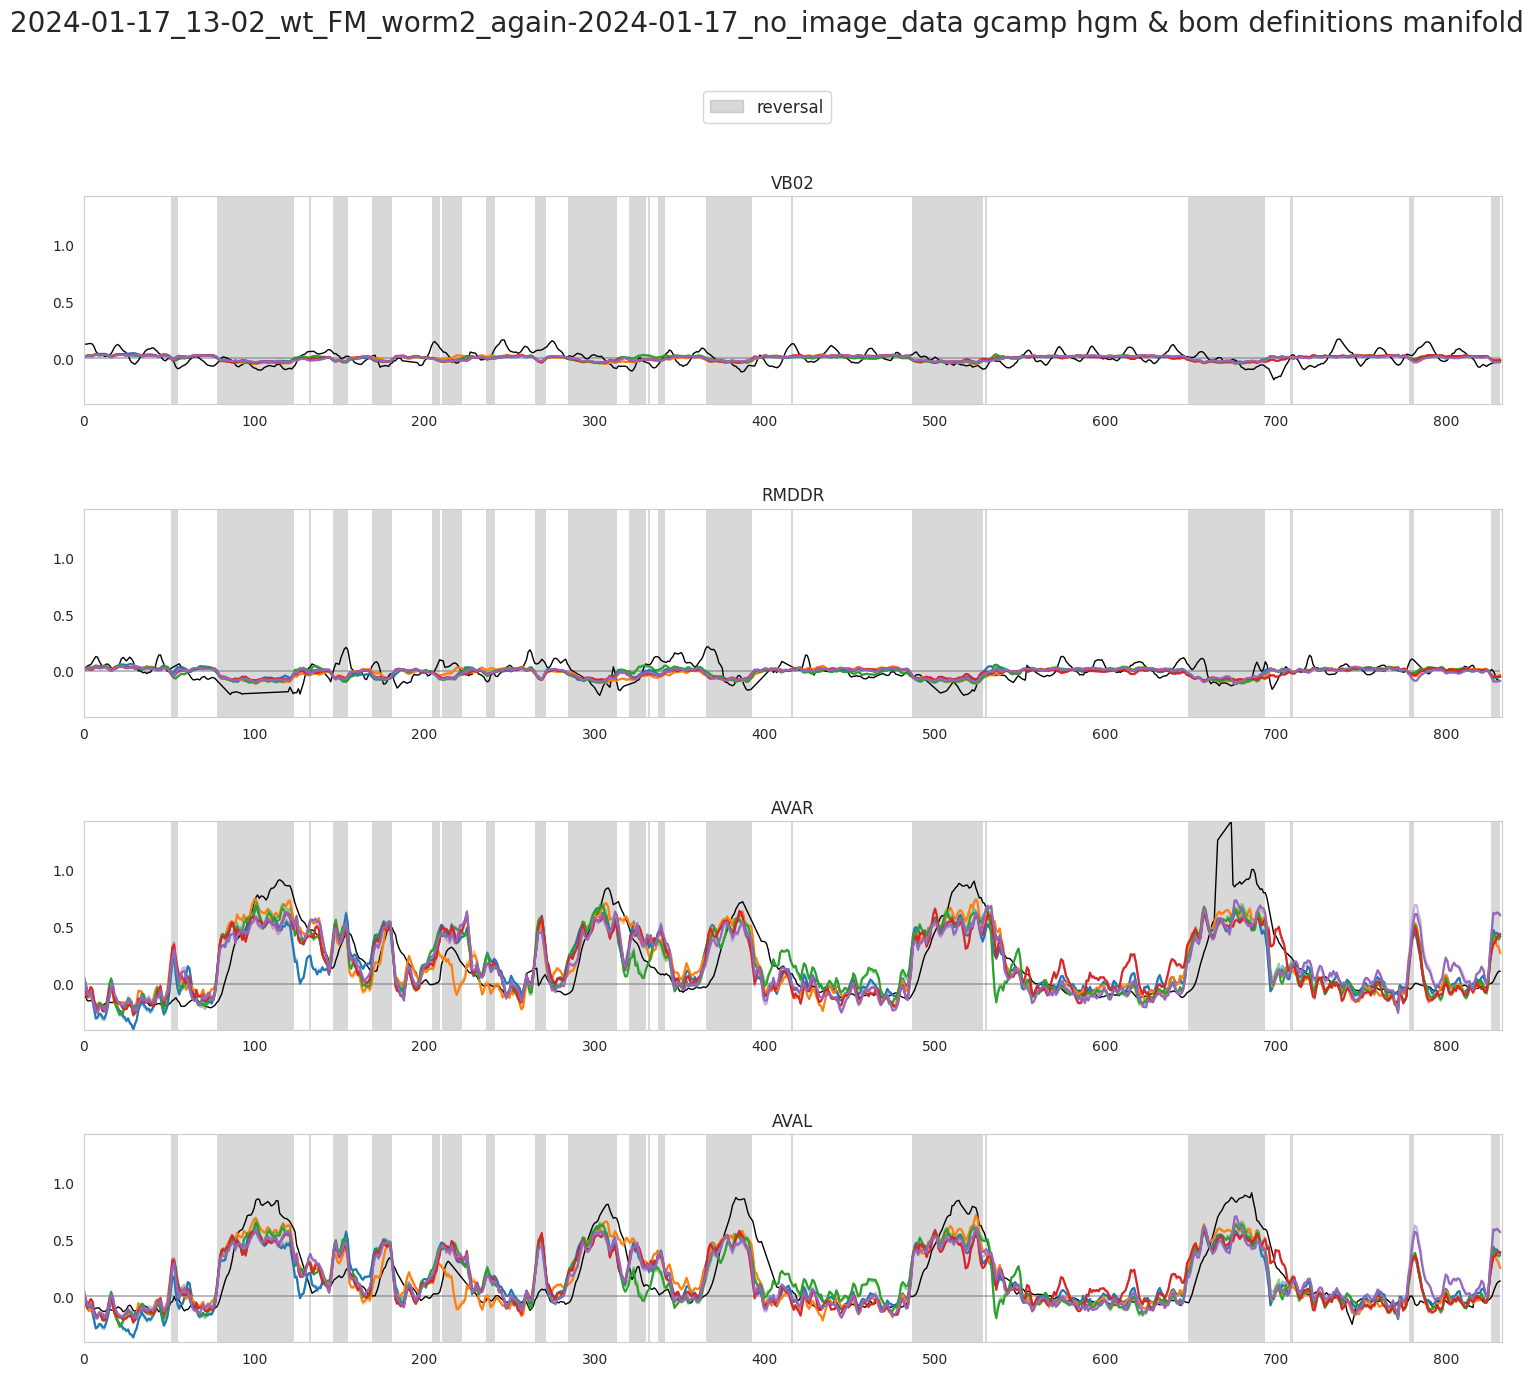

In [46]:
splits = 5
plot_utils.plot_traces_x_splits(
	f'{filenames_gcamp[file_ids_gcamp.index(plot_id)]} gcamp hgm & bom definitions manifold',
	discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
	cca_rec_gcamp[file_ids_gcamp.index(plot_id)][selection_n],
	[hgm_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][2][selection_n] for i in range(splits)],
	[bom_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][2][selection_n] for i in range(splits)],
	plot_first=True, plots_per_row=1, ylimits=None)

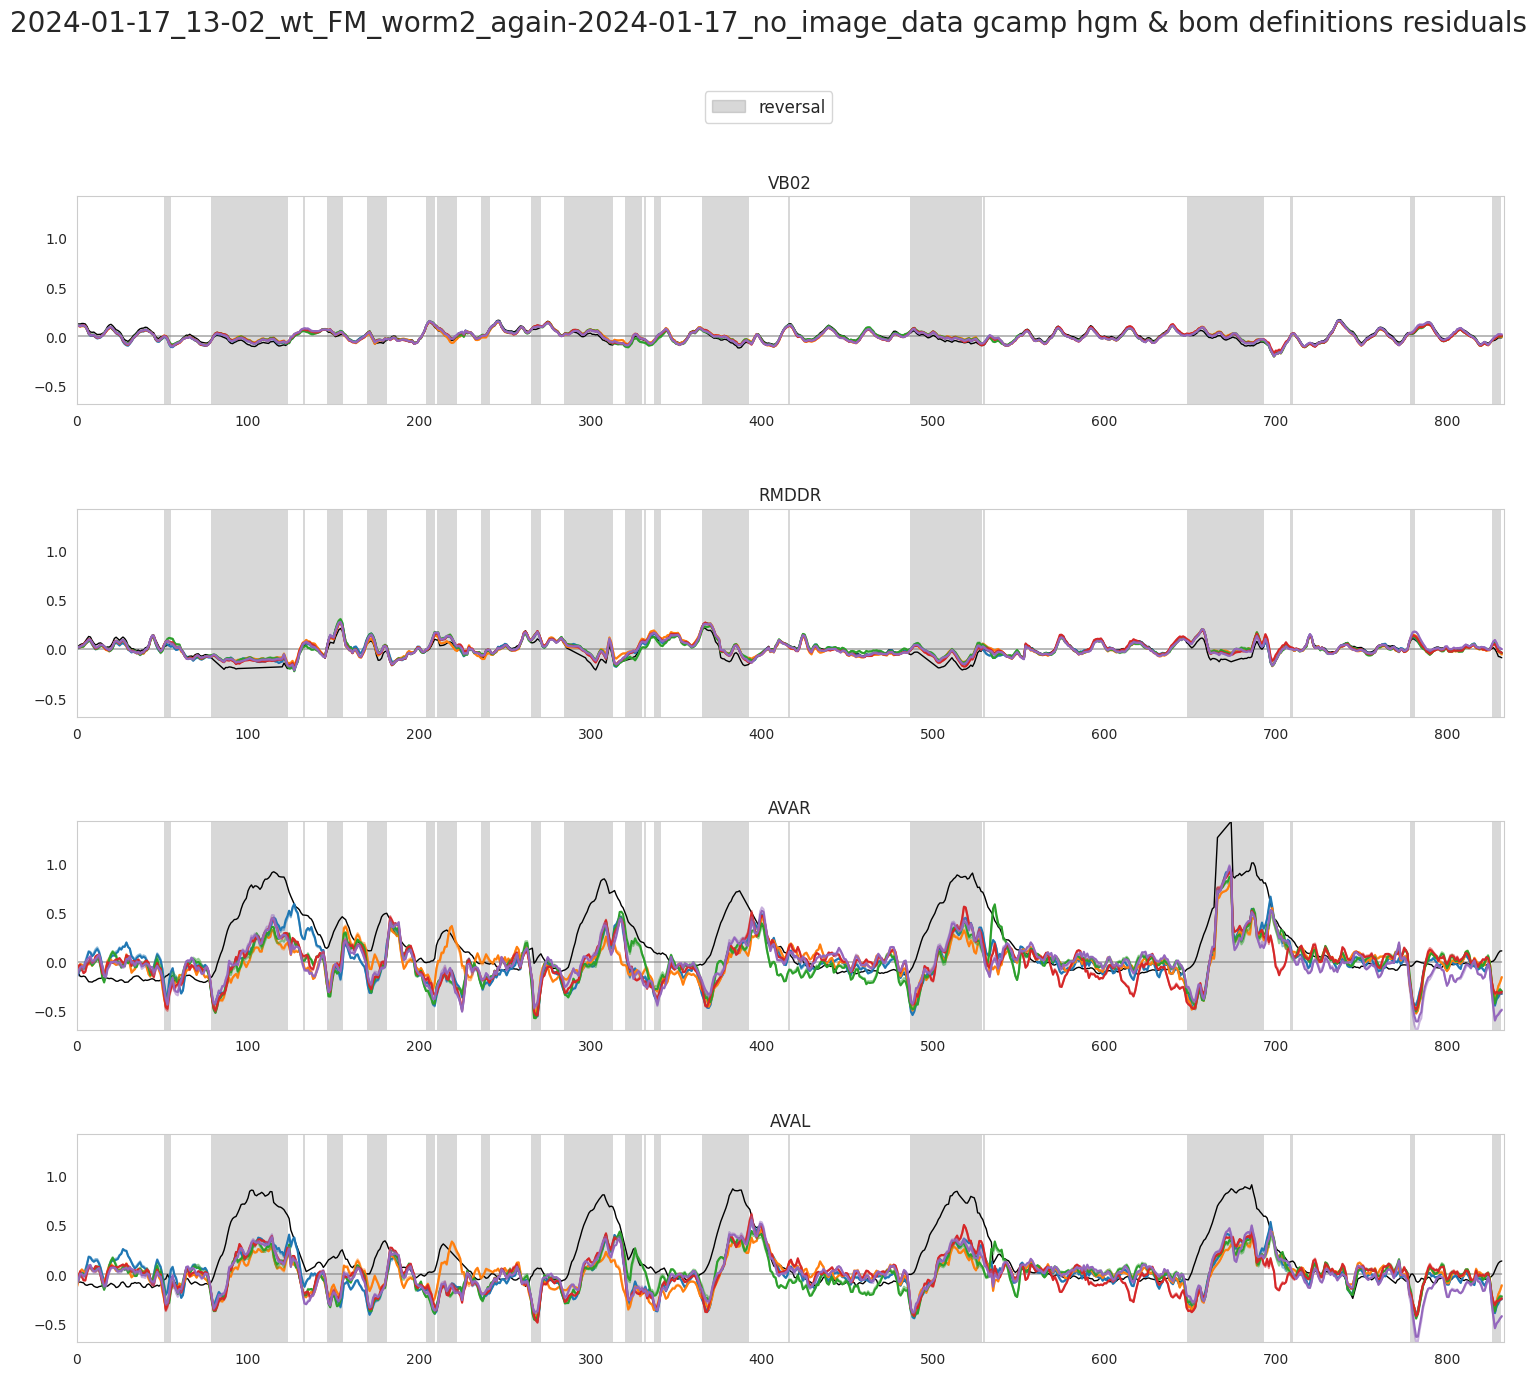

In [47]:
splits = 5
plot_utils.plot_traces_x_splits(
	f'{filenames_gcamp[file_ids_gcamp.index(plot_id)]} gcamp hgm & bom definitions residuals',
	discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
	cca_res_gcamp[file_ids_gcamp.index(plot_id)][selection_n],
	[hgm_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][1][selection_n] for i in range(splits)],
	[bom_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][1][selection_n] for i in range(splits)],
	plot_first=True, plots_per_row=1, ylimits=None)

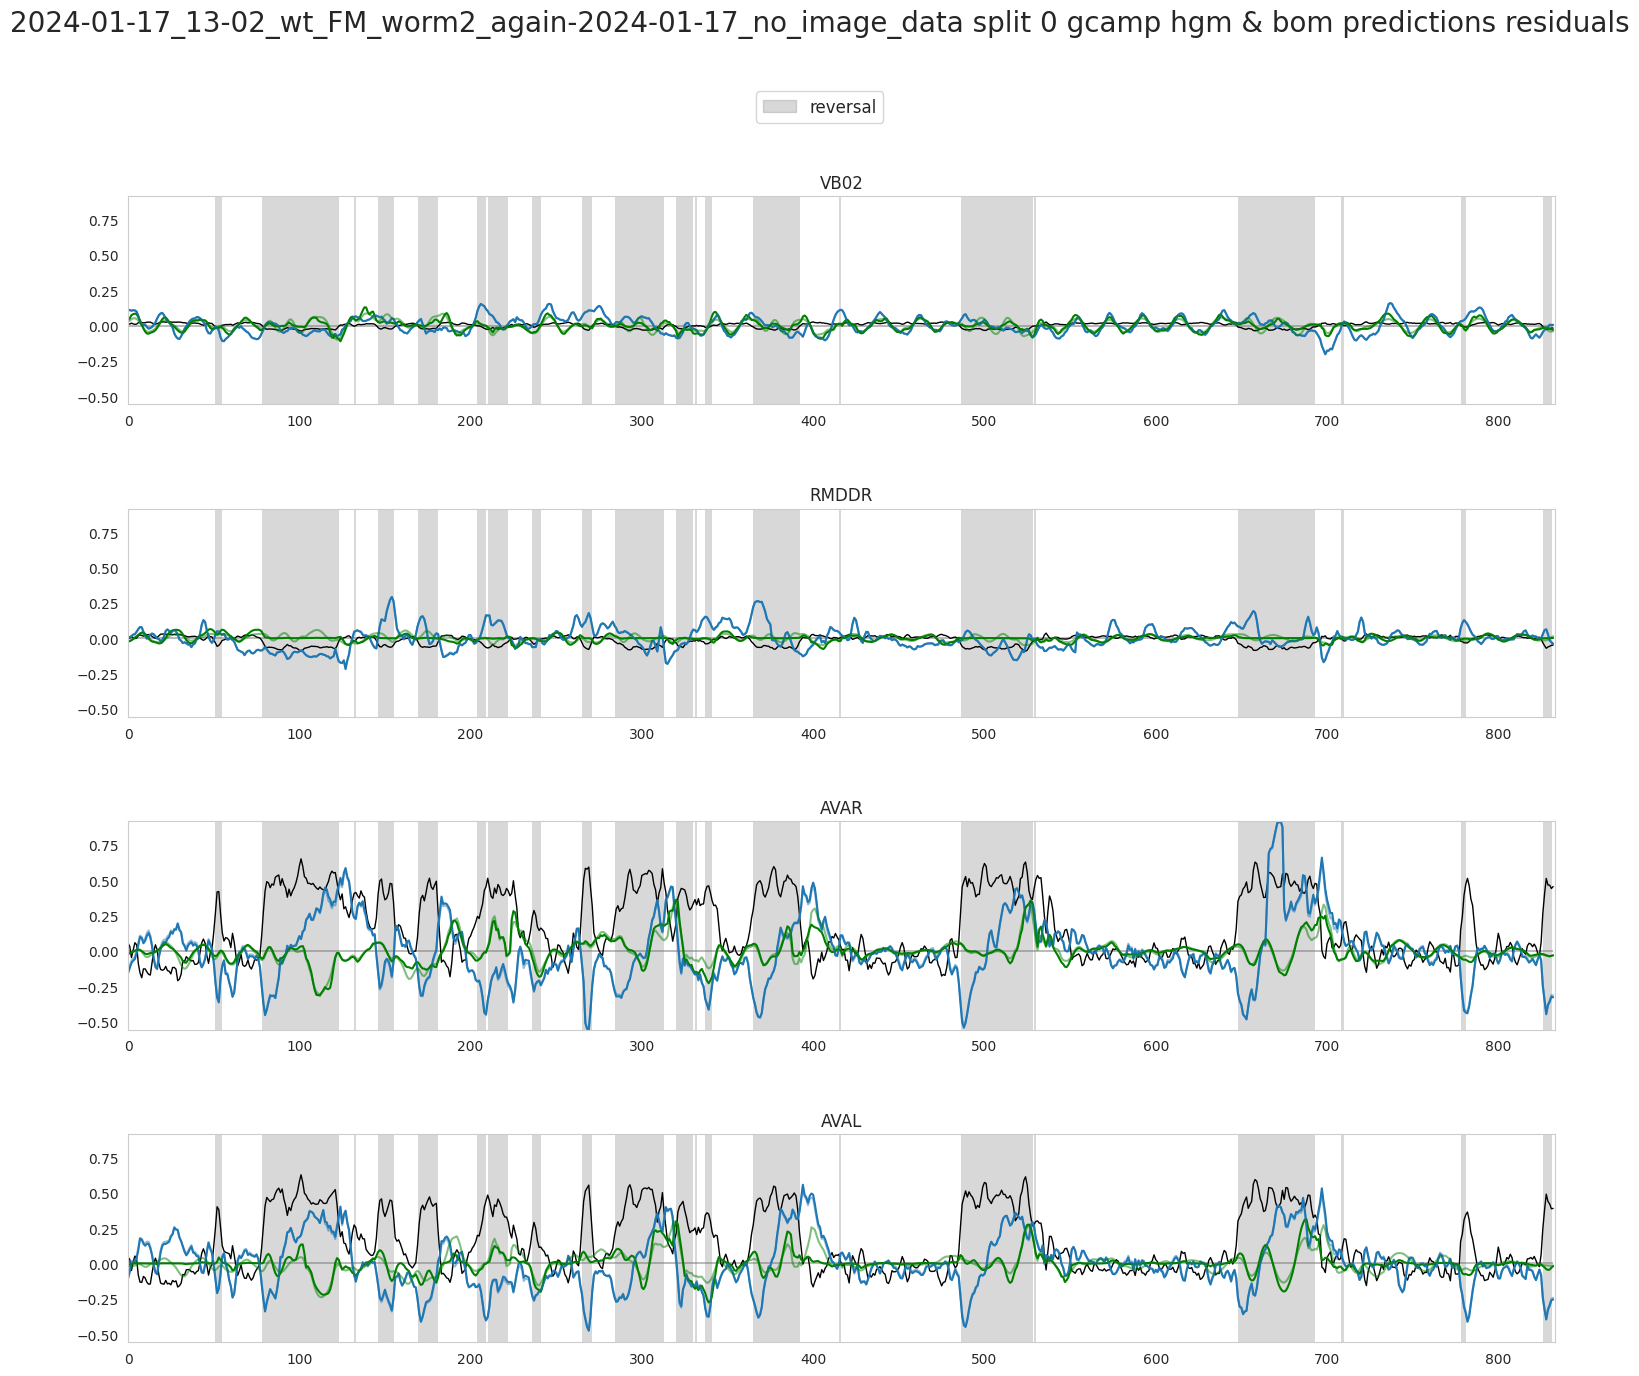

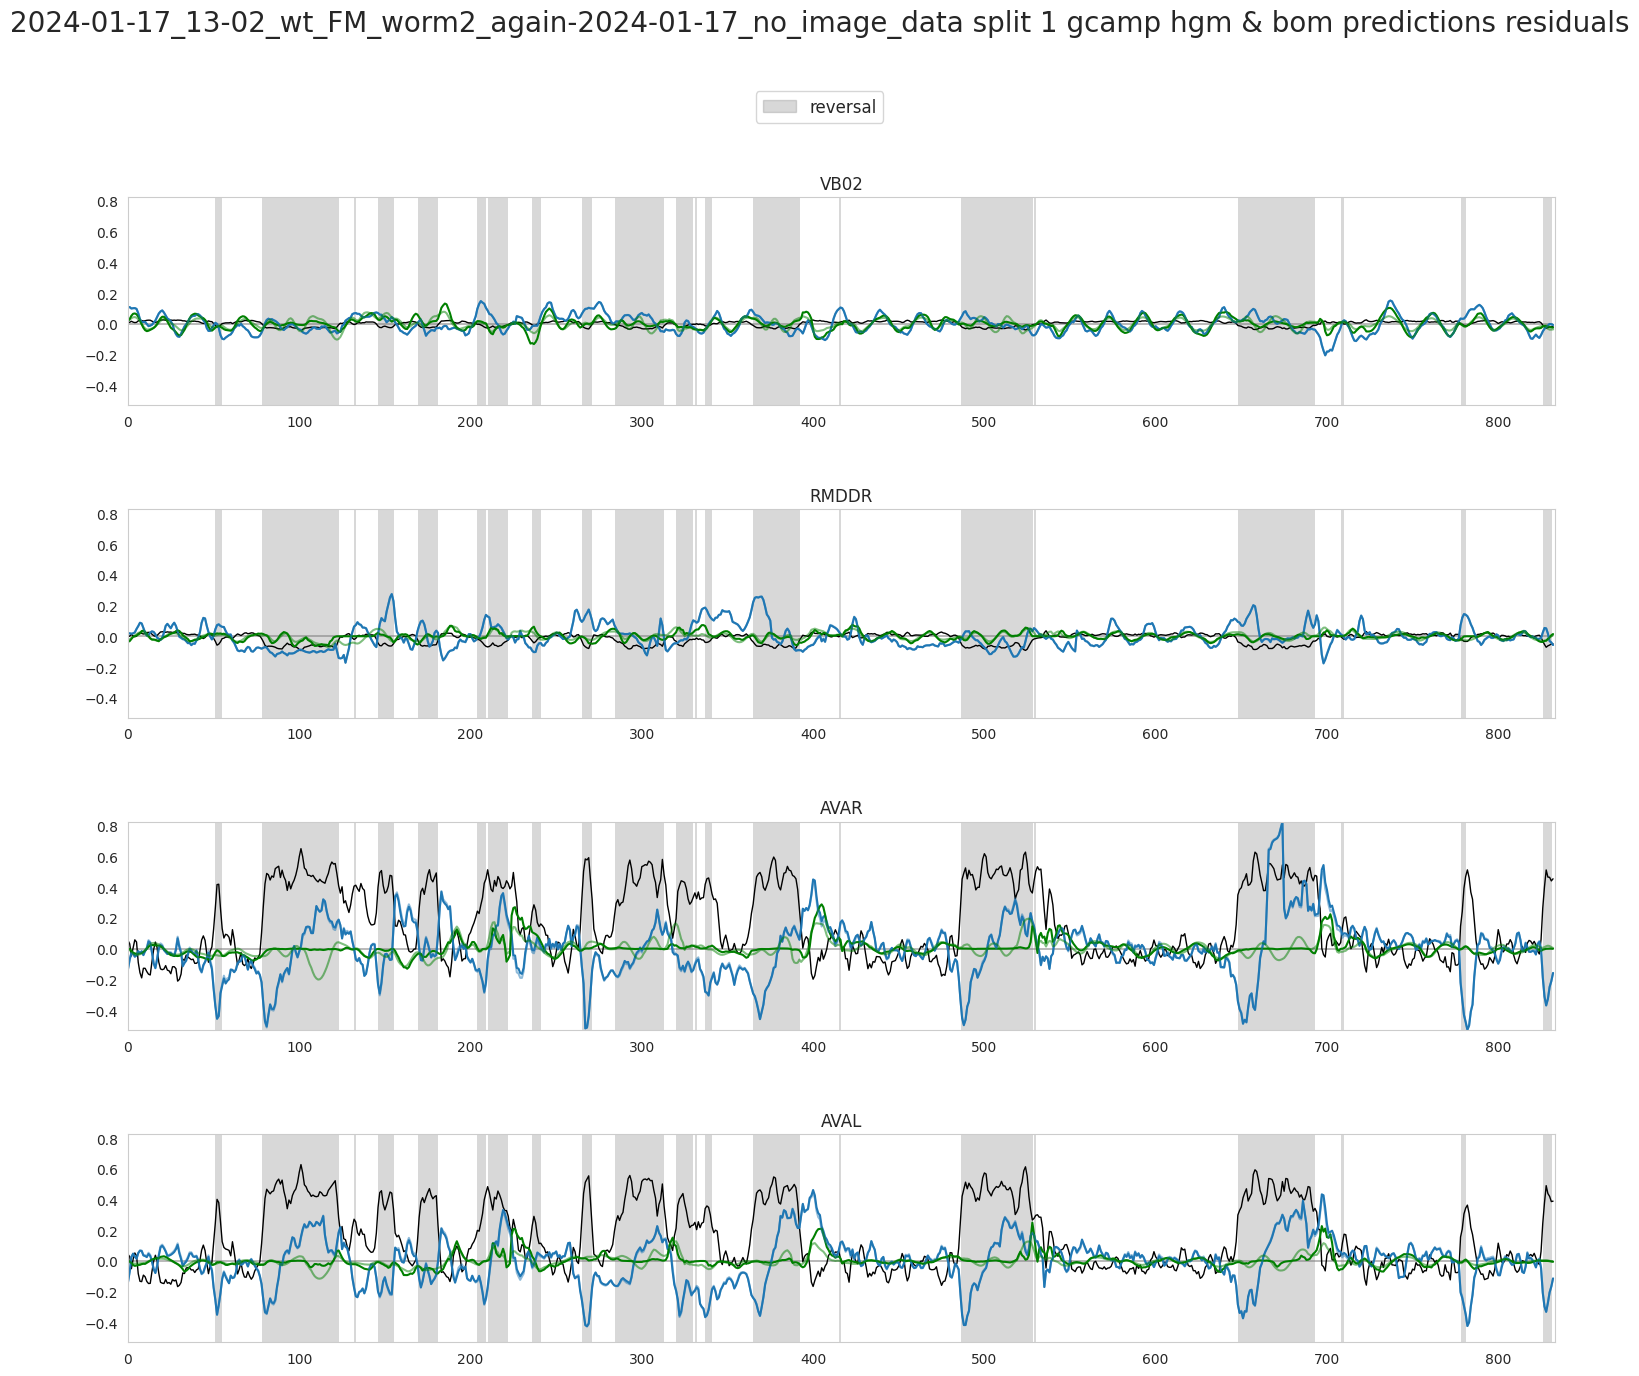

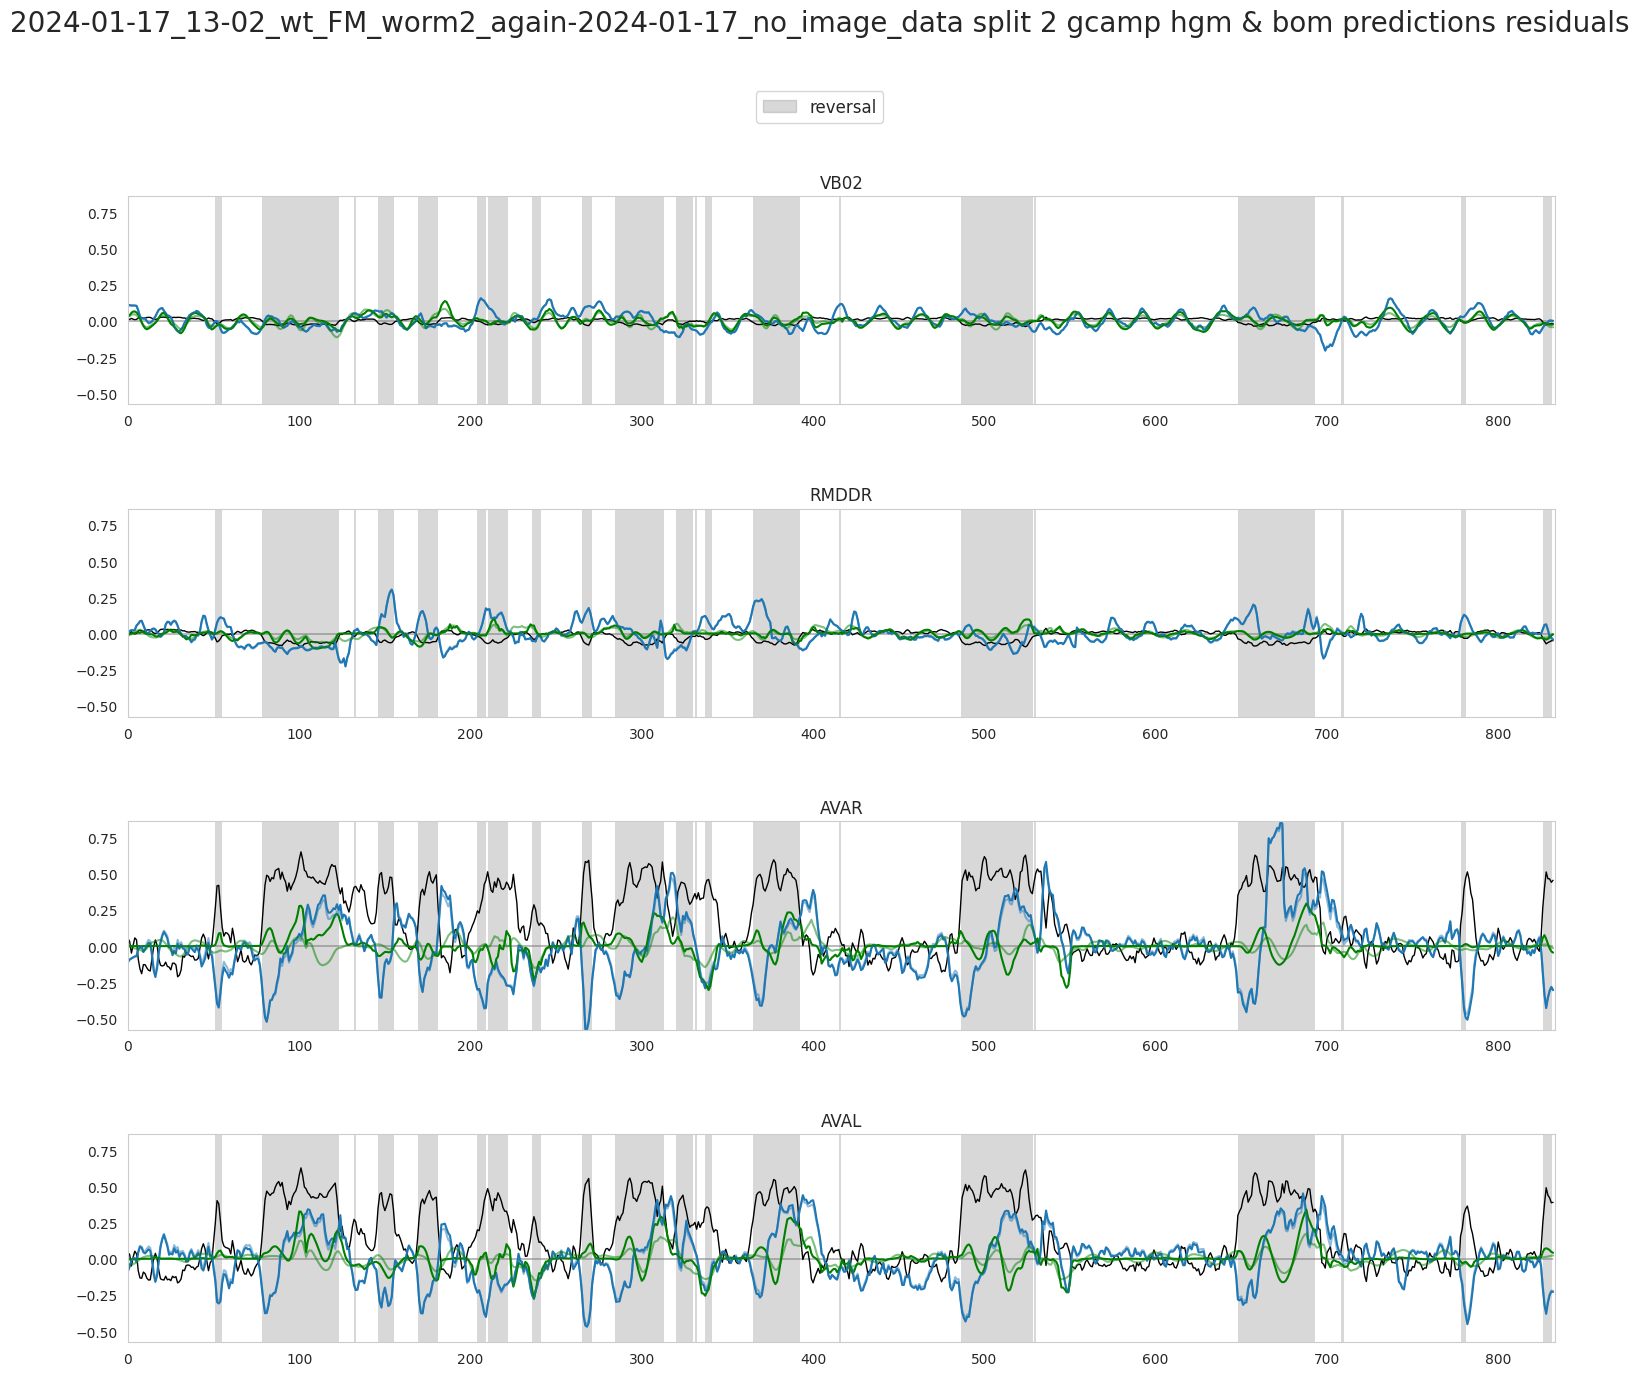

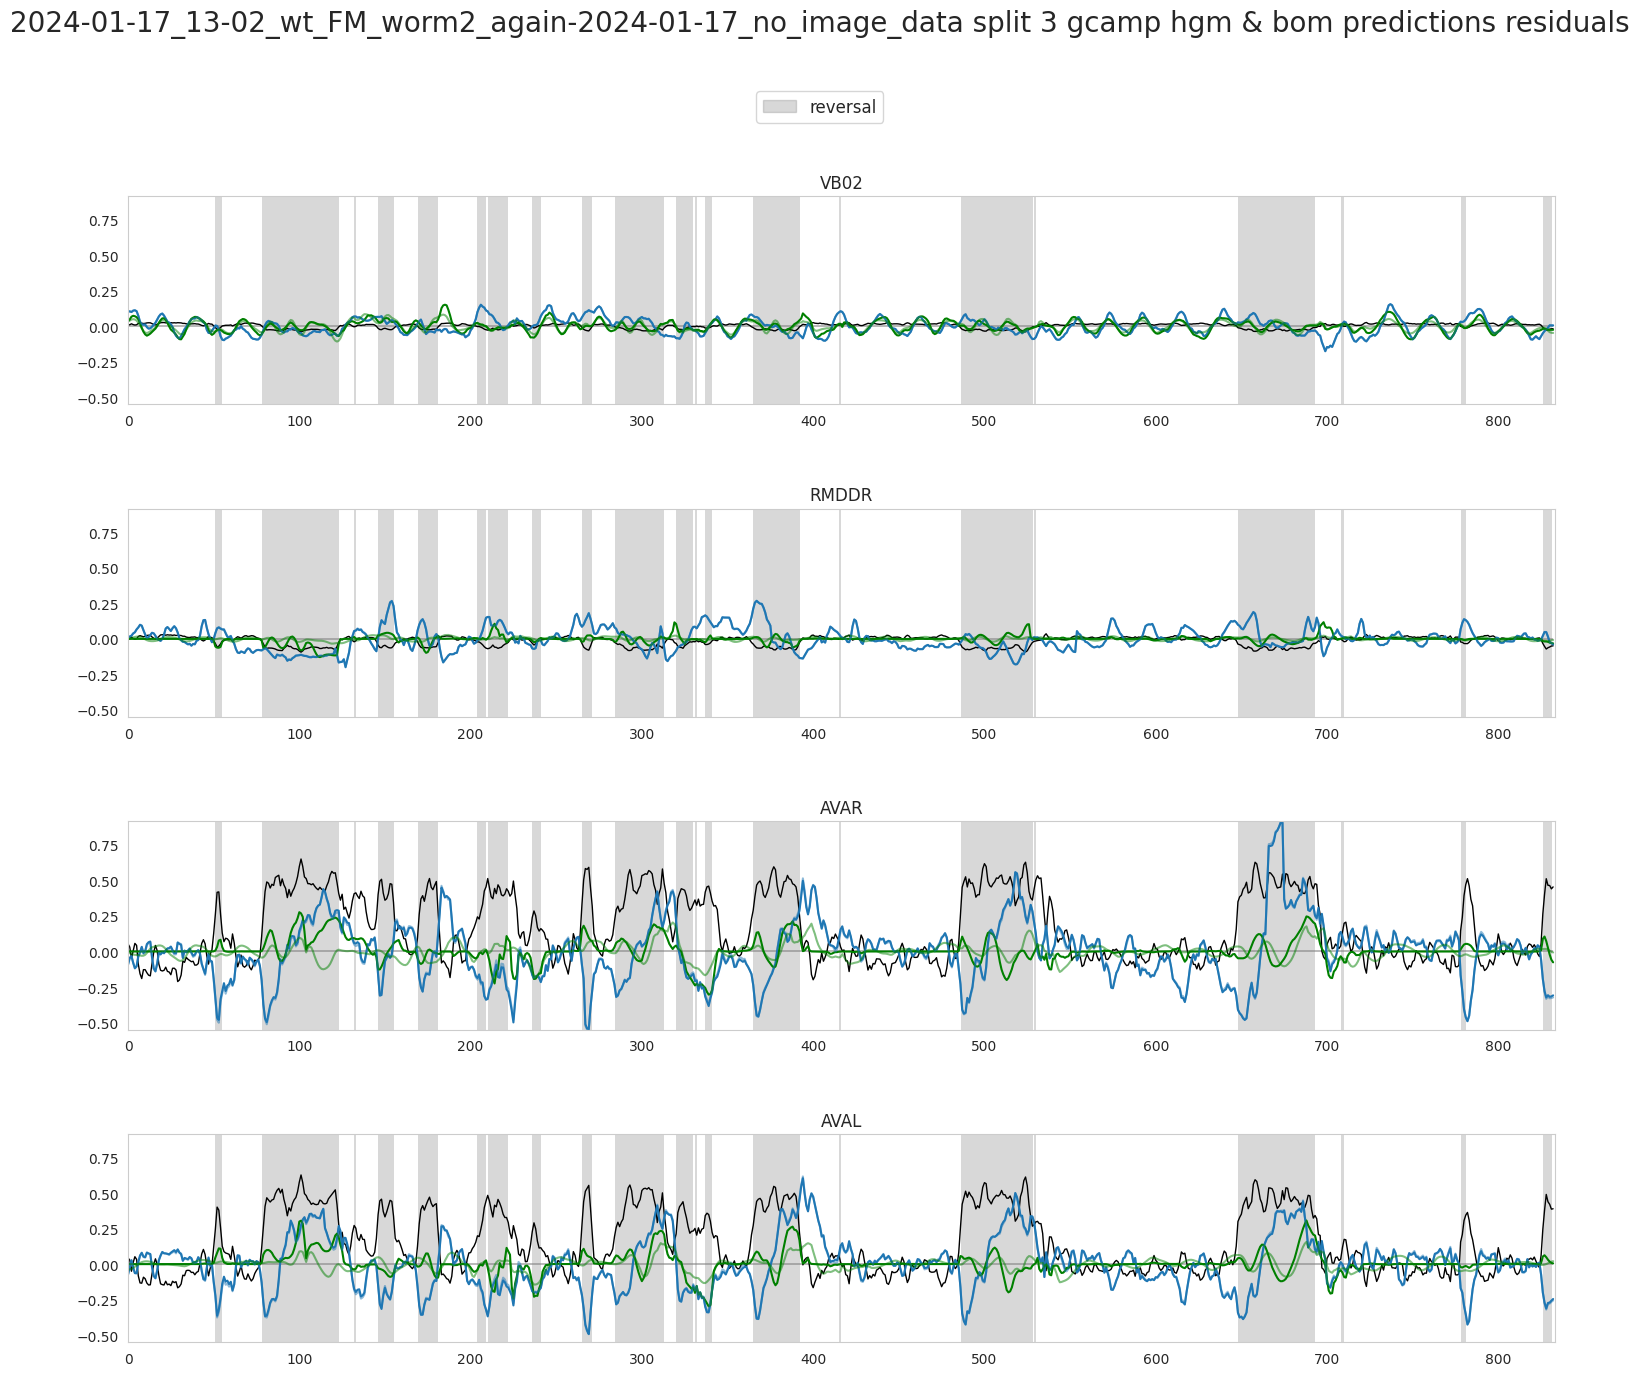

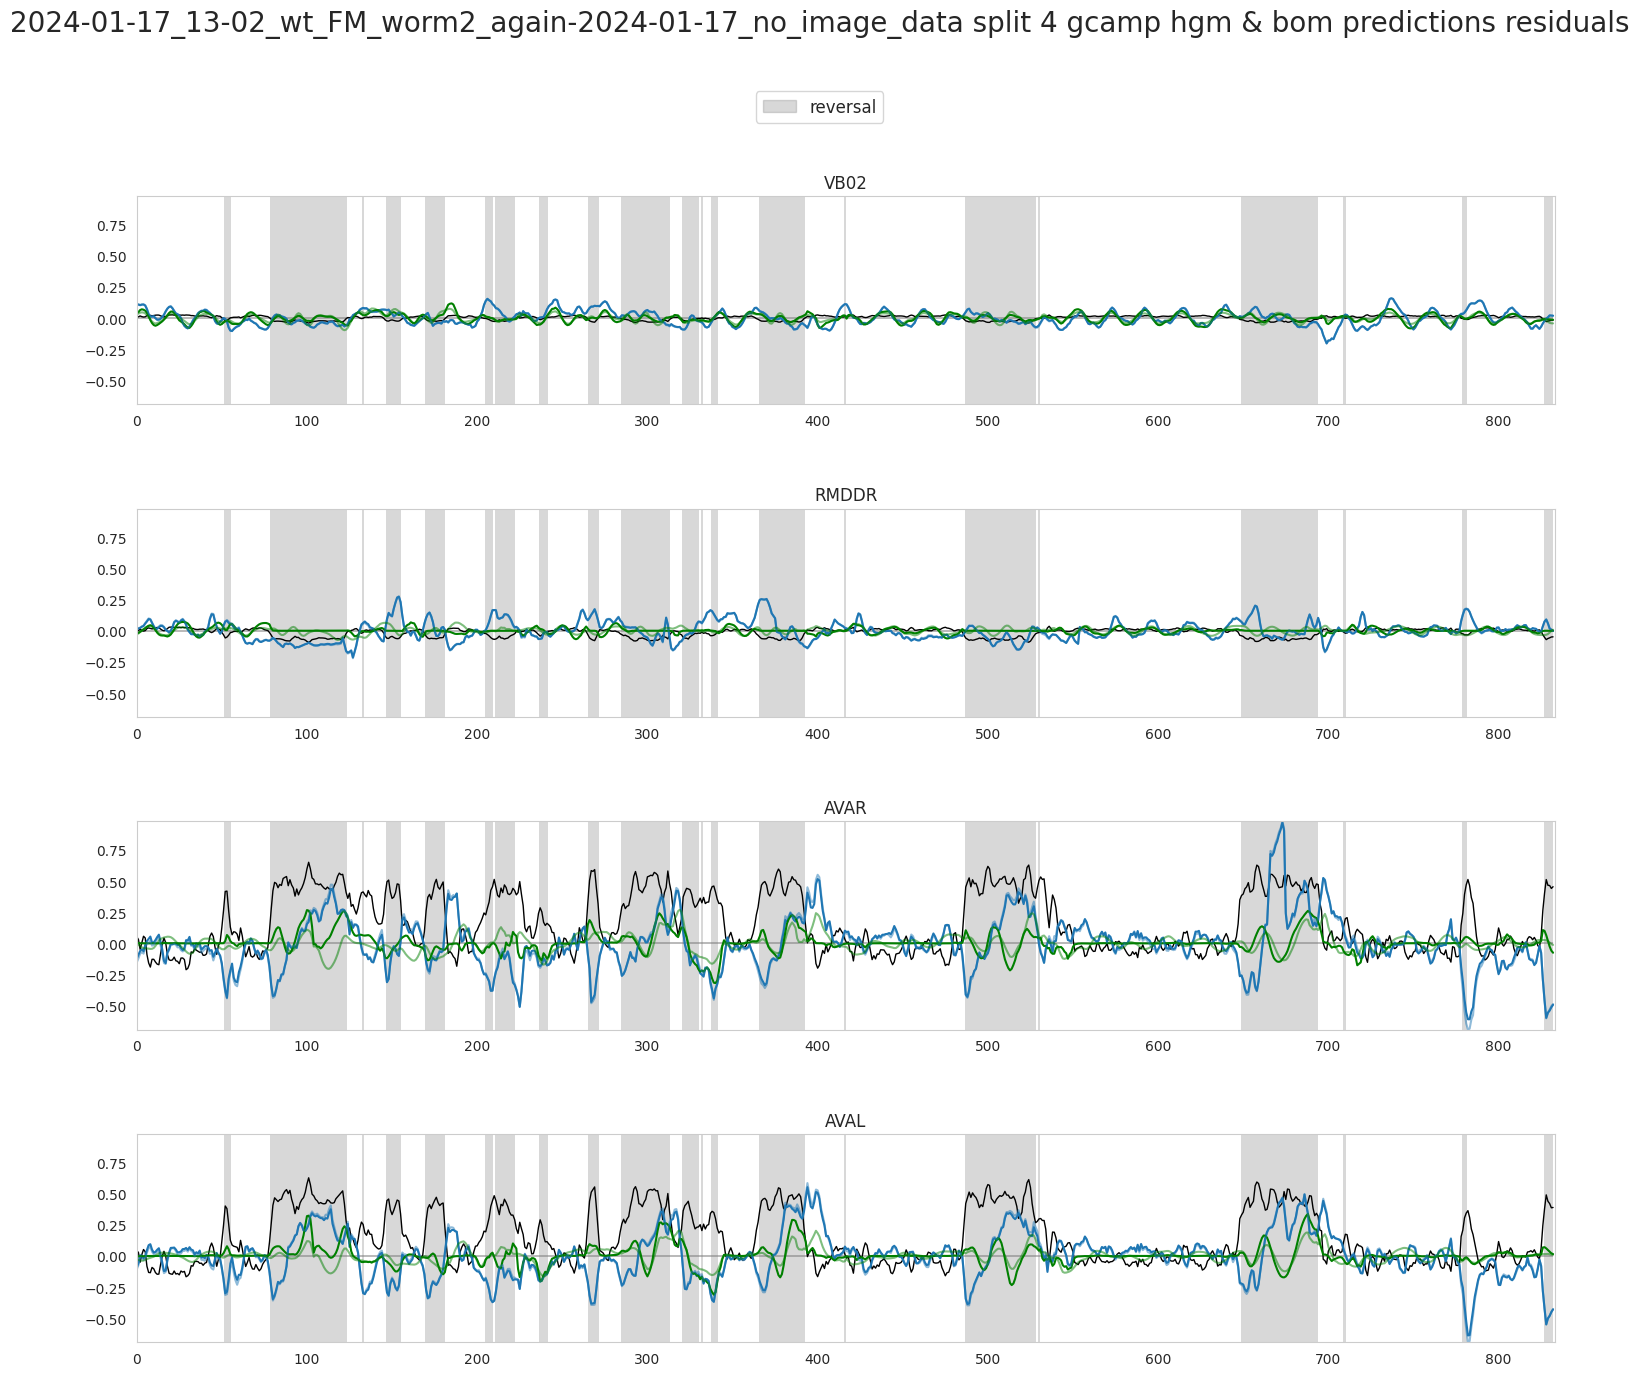

In [51]:
for i in range(5):
	plot_utils.plot_traces_comparisons(
		f'{filenames_gcamp[file_ids_gcamp.index(plot_id)]} split {i} gcamp hgm & bom predictions residuals',
		discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
		cca_res_gcamp[file_ids_gcamp.index(plot_id)][selection_n],
		[hgm_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][1][selection_n],
		 hgm_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][0][selection_n]],
		[bom_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][1][selection_n],
		 bom_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][0][selection_n]],
		plot_first=True, plots_per_row=1, ylimits=None)

# GFP

In [ ]:
if gfp:
	plot_utils.plot_traces(f'[{filenames_gfp[file_ids_gfp.index(plot_id)]}] gfp neural traces residual',
						   discrete_states_gfp[file_ids_gfp.index(plot_id)]['REV'],
						   traces_gfp[file_ids_gfp.index(plot_id)][['VB02', 'AVAR']],
						   plots_per_row=1, ylimits=None)

### BOM

In [ ]:
if gfp:
	(bom_models_params_gfp,
	 bom_models_scores_gfp,
	 bom_models_losses_gfp, bom_models_losses_tr_gfp,
	 bom_models_mpe_losses_gfp, bom_models_mpe_losses_tr_gfp) = train_models(
		bom,
		filenames_gfp,
		discrete_states_gfp,
		eigenworms_gfp,
		traces_gfp)

### HGM

In [ ]:
if gfp:
	(hgm_models_params_gfp,
	 hgm_models_scores_gfp,
	 hgm_models_losses_gfp, hgm_models_losses_tr_gfp,
	 hgm_models_mpe_losses_gfp, hgm_models_mpe_losses_tr_gfp) = train_models(
		hgm,
		filenames_gfp,
		discrete_states_gfp,
		eigenworms_gfp,
		traces_gfp)

In [ ]:
if gfp:
	plot_utils.plot_losses_splits('gfp hgm vs bom: mpe train',
								  filenames_gfp,
								  hgm_models_mpe_losses_tr_gfp, bom_models_mpe_losses_tr_gfp,
								  plots_per_row=4, ylimits=None)

In [ ]:
if gfp:
	plot_utils.plot_losses_splits('gfp hgm vs bom: mpe test',
								  filenames_gfp,
								  hgm_models_mpe_losses_gfp, bom_models_mpe_losses_gfp,
								  plots_per_row=4, ylimits=None)

# assemble

In [ ]:
if gfp:
	neuron_scores_gfp = assemble(filenames_gfp, traces_gfp, bom_models_scores_gfp, hgm_models_scores_gfp)

# Plot

In [ ]:
if gfp:
	plot_utils.plot_performance_plot(neuron_scores_gcamp, neuron_scores_gfp,
									 limits=None, content_size=20, save_name='new/jointmodel-perf-27to33')

In [ ]:
if gfp:
	plot_utils.plot_improvement_plot(neuron_scores_gcamp, neuron_scores_gfp,
									 limits=None, content_size=20, save_name='new/jointmodel-impr-27to33')